---
title: Prediction and Order selection in AR models
---

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf


## Order ($p$) selection for AR($p$)

Let us start with the simple Lake Huron dataset. The Lake Huron dataset contains 98 annual measurements of water levels from 1875 to 1972, recorded in feet. Lake Huron is one of the Great Lakes of North America, and the series captures fluctuations in its water level over nearly a century

   Unnamed: 0       x
0           1  580.38
1           2  581.86
2           3  580.97
3           4  580.80
4           5  579.79


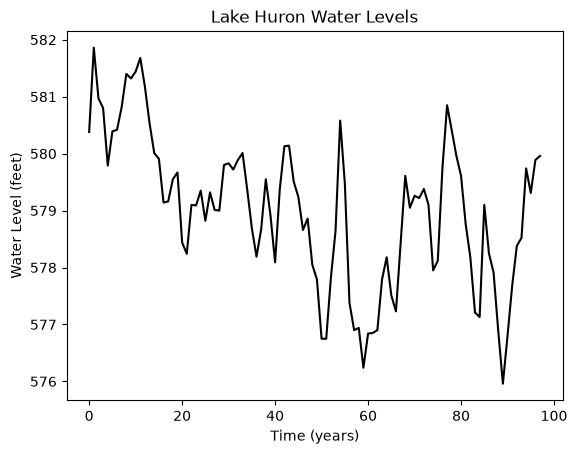

In [60]:
LakeHuron = pd.read_csv("LakeHuron.csv")
print(LakeHuron.head())
y = LakeHuron.iloc[:, -1].to_numpy()
plt.plot(y, color = 'black')
plt.xlabel('Time (years)')
plt.ylabel('Water Level (feet)')
plt.title('Lake Huron Water Levels')
plt.show()

Here is an approach that we can use to select the order $p$ in AR($p$). 

For each $p = 1, \ldots, p_{\max}$, we fit an AR($p$) model to the logarithms of the training data. We record $\widehat{\phi}_{p,p}$, the estimated coefficient of the last lag in that model, together with its approximate 95% confidence interval. We then plot these estimates and intervals against $p$.

The idea is that if the data follow an AR($p_0$) model, additional lags beyond $p_0$ have zero coefficients. We therefore look for a cutoff after which the estimates fluctuate near zero, with most of their confidence intervals containing zero. The location of this cutoff suggests a suitable AR order.

This is a heuristic. We examine the entire plot rather than stopping at the first interval containing zero, because later coefficients may still be substantial. Conversely, an isolated interval excluding zero at a large lag may occur simply by chance when many orders are examined. The suggested order can be assessed further by checking residuals and comparing forecasting performance.

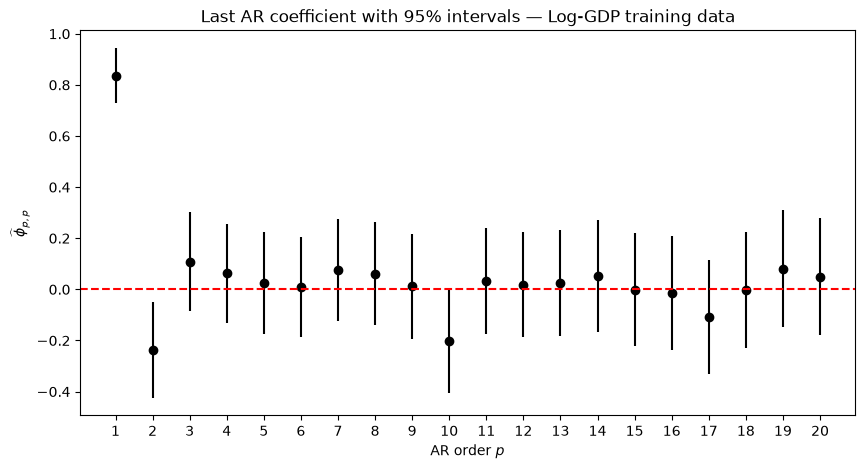

In [61]:
p_max = 20  # Choose the maximum AR order
p_values = range(1, p_max + 1)
phi, ci = [], []

for p in p_values:
    fit = AutoReg(y, lags = p).fit()
    phi.append(fit.params[-1])
    ci.append(fit.conf_int()[-1])

ci = np.array(ci)

plt.figure(figsize=(10, 5))
plt.plot(p_values, phi, 'ko')
plt.vlines(p_values, ci[:, 0], ci[:, 1], color='black')
plt.axhline(0, color='red', linestyle='--')
plt.xticks(p_values)
plt.xlabel('AR order $p$')
plt.ylabel(r'$\widehat{\phi}_{p,p}$')
plt.title('Last AR coefficient with 95% intervals — Log-GDP training data')
plt.show()

This plot clearly suggests AR(2). 

In [62]:
p = 2
n = len(y)
k = 20
armod_sm = AutoReg(y, lags = p).fit()
print(armod_sm.summary())
fcast = armod_sm.get_prediction(start = n, end = n+k-1)
fcast_mean = fcast.predicted_mean

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                   98
Model:                     AutoReg(2)   Log Likelihood                 -98.311
Method:               Conditional MLE   S.D. of innovations              0.674
Date:                Tue, 03 Nov 2026   AIC                            204.622
Time:                        19:13:47   BIC                            214.879
Sample:                             2   HQIC                           208.768
                                   98                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        124.9499     31.558      3.959      0.000      63.098     186.802
y.L1           1.0217      0.096     10.650      0.000       0.834       1.210
y.L2          -0.2376      0.096     -2.485      0.0

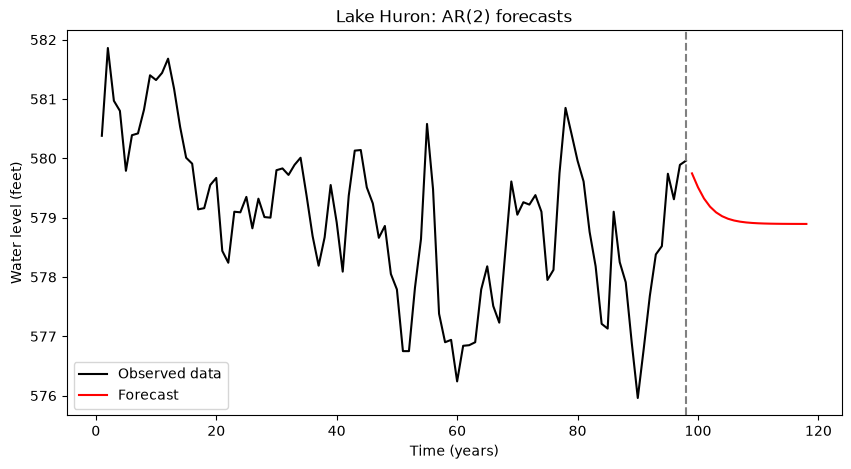

In [63]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, n+1), y, color='black', label='Observed data')
plt.plot(range(n+1, n+k+1), fcast_mean, color='red', label='Forecast')
plt.axvline(x=n, color='gray', linestyle='--')
plt.xlabel('Time (years)')
plt.ylabel('Water level (feet)')
plt.title(f'Lake Huron: AR({p}) forecasts')
plt.legend()
plt.show()

For a second example, let us look at the GDP data from last lecture. 

The following data is on US GDP from FRED (https://fred.stlouisfed.org/series/GDP). It measures the market value of the goods and services produced by labor and property located in the United States. It is in the units of billions of dollars (with seasonal adjustment but no adjustment for inflation). Compiled by the Bureau of Economic Analysis (BEA), GDP is a broad measure of U.S. economic output and is used to track overall economic activity.

  observation_date      GDP
0       1947-01-01  243.164
1       1947-04-01  245.968
2       1947-07-01  249.585
3       1947-10-01  259.745
4       1948-01-01  265.742


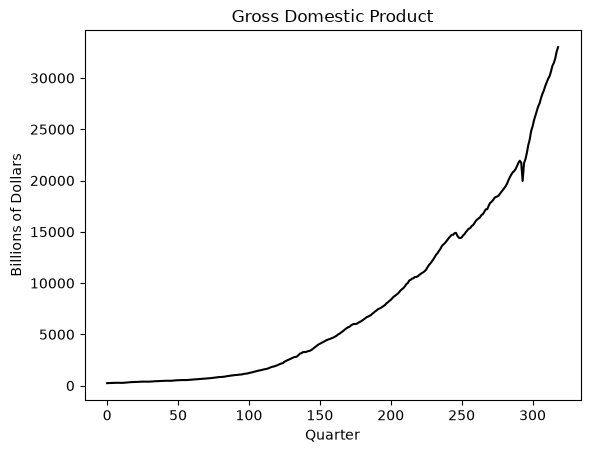

In [64]:
gdp = pd.read_csv("GDP_29Oct2026.csv")
print(gdp.head())
y = gdp['GDP'].to_numpy()
plt.plot(y, color = 'black')
plt.xlabel('Quarter')
plt.ylabel('Billions of Dollars')
plt.title('Gross Domestic Product')
plt.show()

As in the last lecture, we split the data into training and test sets. 

In [65]:
n = len(y)
tme = range(1, n+1)
n_test = 50
#n_test = 12 
n_train = n - n_test
y_train = y[:n_train]
tme_train = tme[:n_train]
y_test = y[n_train:]
tme_test = tme[n_train:]

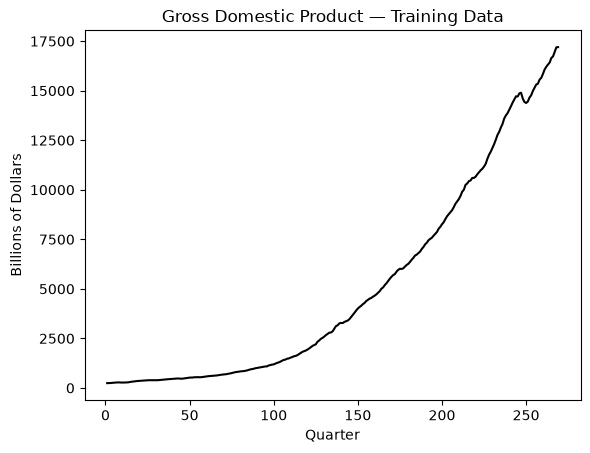

In [66]:
plt.plot(tme_train, y_train, color='black')
plt.xlabel('Quarter')
plt.ylabel('Billions of Dollars')
plt.title('Gross Domestic Product — Training Data')
plt.show()

In the last lecture, we fit AR(1) to logarithms of the raw data. 

In [67]:
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

Instead of fitting AR(1) as in the last lecture, let us choose $p$ using the aforementioned approach. 

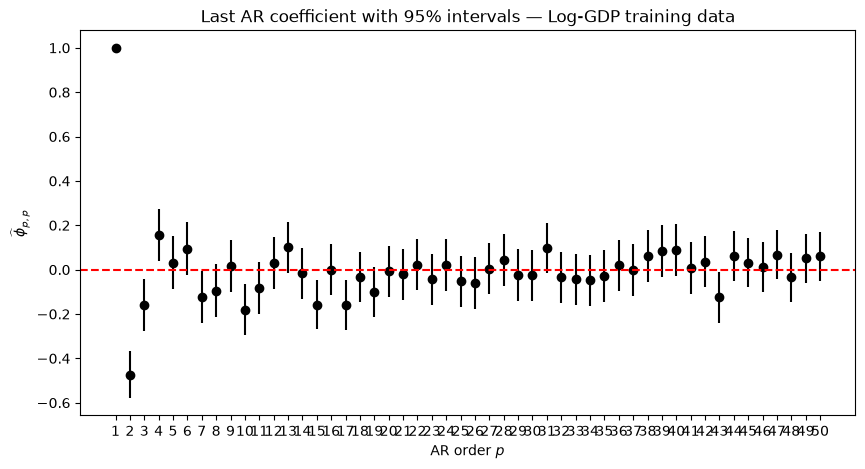

In [69]:
y = ylog_train
p_max = 50  # Choose the maximum AR order
p_values = range(1, p_max + 1)
phi, ci = [], []

for p in p_values:
    fit = AutoReg(y, lags = p).fit()
    phi.append(fit.params[-1])
    ci.append(fit.conf_int()[-1])

ci = np.array(ci)

plt.figure(figsize=(10, 5))
plt.plot(p_values, phi, 'ko')
plt.vlines(p_values, ci[:, 0], ci[:, 1], color='black')
plt.axhline(0, color='red', linestyle='--')
plt.xticks(p_values)
plt.xlabel('AR order $p$')
plt.ylabel(r'$\widehat{\phi}_{p,p}$')
plt.title('Last AR coefficient with 95% intervals — Log-GDP training data')
plt.show()

Plausible values for $p$ based on the above plot are $p = 4, 10, 15, 17$. We can fit the AR($p$) model for all these values of $p$, obtain predictions on the test data, and see which value of $p$ gives the smallest prediction error (say measured in terms of the mean-squared error). 

In [71]:
#p_values = [4, 10, 15, 17]
p_values = range(1, p_max + 1)
k = n_test
predictions = {}
mse = []

for p in p_values:
    armod_sm = AutoReg(ylog_train, lags = p).fit()
    fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
    fcast_mean = fcast.predicted_mean

    predictions[p] = fcast_mean
    mse.append(np.mean((ylog_test - fcast_mean)**2))

# Compare MSE: smaller is better
results = pd.DataFrame({'p': p_values, 'Log-scale MSE': mse})
print(results.sort_values('Log-scale MSE').to_string(index=False))

 p  Log-scale MSE
 4       0.001558
 7       0.001578
 5       0.001587
 6       0.001608
 2       0.001721
 1       0.001821
 3       0.001916
 8       0.001959
 9       0.002478
14       0.003282
13       0.003308
16       0.004008
10       0.004147
15       0.004253
11       0.004817
12       0.005002
17       0.005616
18       0.006068
19       0.007324
20       0.007730
21       0.009167
22       0.009454
24       0.009748
23       0.011959
25       0.012926
31       0.017770
26       0.018809
28       0.019168
32       0.020210
27       0.020217
41       0.020994
40       0.022058
29       0.022638
33       0.023289
39       0.024664
38       0.024874
30       0.025594
43       0.026162
34       0.026476
36       0.027247
42       0.027776
37       0.028672
35       0.028744
48       0.035098
44       0.036289
50       0.037310
49       0.038225
47       0.038969
45       0.045061
46       0.045665


$p = 4$ seems to give the smallest prediction error. So we will therefore fit AR(4). 

In [72]:
p = 4
armod_sm = AutoReg(ylog_train, lags = p).fit()
print(armod_sm.summary())
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives the point predictions

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  269
Model:                     AutoReg(4)   Log Likelihood                 863.305
Method:               Conditional MLE   S.D. of innovations              0.009
Date:                Tue, 03 Nov 2026   AIC                          -1714.610
Time:                        19:18:07   BIC                          -1693.131
Sample:                             4   HQIC                         -1705.980
                                  269                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0141      0.004      3.654      0.000       0.007       0.022
y.L1           1.4221      0.060     23.637      0.000       1.304       1.540
y.L2          -0.1959      0.103     -1.904      0.0

## Calculation of AR Prediction Uncertainties

Prediction uncertainty intervals are obtained as follows. 

In [73]:
fcast_se = fcast.se_mean
alpha = 0.05
z_alpha_half = stats.norm.ppf(1 - alpha/2)
predlower = fcast_mean - z_alpha_half * fcast_se
predupper = fcast_mean + z_alpha_half * fcast_se
fcast_int = fcast.conf_int()
print(np.column_stack([predlower, predupper, fcast_int]))

[[ 9.7419066   9.77840016  9.7419066   9.77840016]
 [ 9.73594519  9.79938948  9.73594519  9.79938948]
 [ 9.73289739  9.82491998  9.73289739  9.82491998]
 [ 9.73254927  9.8485642   9.73254927  9.8485642 ]
 [ 9.73463353  9.87182698  9.73463353  9.87182698]
 [ 9.73816641  9.89351037  9.73816641  9.89351037]
 [ 9.74283825  9.9143182   9.74283825  9.9143182 ]
 [ 9.74820306  9.93417468  9.74820306  9.93417468]
 [ 9.75412806  9.95342189  9.75412806  9.95342189]
 [ 9.76045249  9.9721292   9.76045249  9.9721292 ]
 [ 9.76712003  9.99044328  9.76712003  9.99044328]
 [ 9.77406543 10.00841425  9.77406543 10.00841425]
 [ 9.78125559 10.02610364  9.78125559 10.02610364]
 [ 9.78865563 10.04354084  9.78865563 10.04354084]
 [ 9.79624191 10.06075601  9.79624191 10.06075601]
 [ 9.803992   10.07776869  9.803992   10.07776869]
 [ 9.81188849 10.09459744  9.81188849 10.09459744]
 [ 9.81991581 10.11125668  9.81991581 10.11125668]
 [ 9.82806109 10.12775953  9.82806109 10.12775953]
 [ 9.83631301 10.14411699  9.83

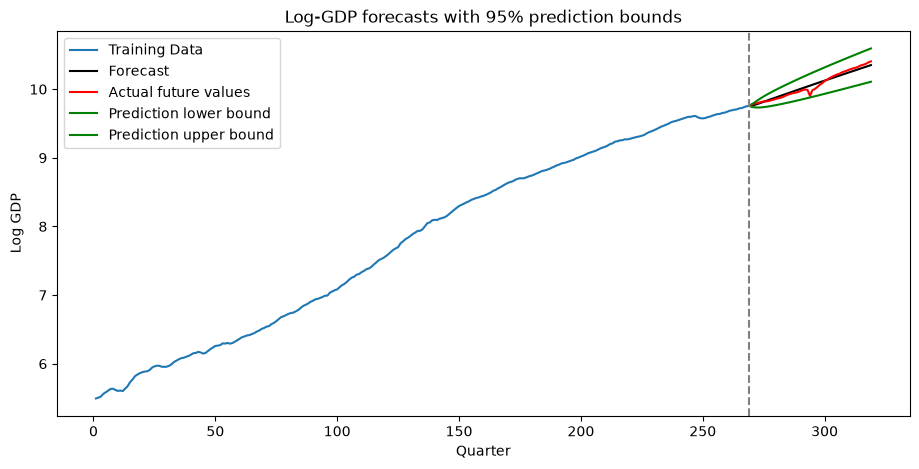

In [74]:
plt.figure(figsize=(11, 5))
plt.plot(tme_train, ylog_train, label='Training Data')
plt.plot(tme_test, fcast_mean, color='black', label='Forecast')
plt.plot(tme_test, ylog_test, color='red', label='Actual future values')
plt.plot(tme_test, predlower, color='green', label='Prediction lower bound')
plt.plot(tme_test, predupper, color='green', label='Prediction upper bound')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.xlabel('Quarter')
plt.ylabel('Log GDP')
plt.title('Log-GDP forecasts with 95% prediction bounds')
plt.legend()
plt.show()

We now calculate the prediction standard errors directly using the method described in class. The first step is to fit the AR(p) model and then to obtain estimates of $\phi_0, \dots, \phi_p$ as well as $\sigma$. There are two estimates of $\sigma$ (only difference being the denominators: $n-p$ vs $n-2p-1$).

In [75]:
yreg = ylog_train[p:] #these are the response values in the autoregression
Xmat = np.ones((n_train-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = ylog_train[p-j : n_train-j]
    Xmat = np.column_stack([Xmat, col])

armod = sm.OLS(yreg, Xmat).fit()
sighat = np.sqrt(np.mean(armod.resid ** 2)) #note that this mean is taken over n-p observations (this is the MLE for sigma)
resdf = n_train - 2*p - 1
sigols = np.sqrt((np.sum(armod.resid ** 2))/resdf)
print(sighat, sigols)

0.009309753791217517 0.00939884437415018


The two estimates of $\sigma$ lead to two values for standard errors. 

In [76]:
covmat = (sighat ** 2) * np.linalg.inv(np.dot(Xmat.T, Xmat))
covmat_ols = (sigols ** 2) * np.linalg.inv(np.dot(Xmat.T, Xmat))
print(np.sqrt(np.diag(covmat)))
print(armod_sm.bse)
print(np.sqrt(np.diag(covmat_ols)))
print(armod.bse)

[0.00386884 0.06016541 0.10289134 0.10286516 0.0600113 ]
[0.00386884 0.06016541 0.10289134 0.10286516 0.0600113 ]
[0.00390586 0.06074117 0.10387597 0.10384954 0.06058558]
[0.00390586 0.06074117 0.10387597 0.10384954 0.06058558]


The following code computes the prediction standard errors. It uses the matrix recursion method described in class. 

In [77]:
sigest = sighat
Gamhat = np.array([[sigest ** 2]])
vkp = np.array([[armod.params[1]]])

for i in range(1, k):
    covterm = Gamhat @ vkp 
    varterm = sigest**2 + (vkp.T @ (Gamhat @ vkp)) 
    Gamhat = np.block([
        [Gamhat,    covterm],
        [covterm.T, varterm ]
    ])
    if i < p:
        new_coef = armod.params[i+1]
        vkp = np.vstack([ [new_coef], vkp ])
    else:
        vkp = np.vstack([ [0], vkp ])
predsd = np.sqrt(np.diag(Gamhat))

#Check that this method produces the same standard errors as those computed by .se_mean:
print(np.column_stack([predsd, fcast_se]))

[[0.00930975 0.00930975]
 [0.01618506 0.01618506]
 [0.02347558 0.02347558]
 [0.02959619 0.02959619]
 [0.03499897 0.03499897]
 [0.03962929 0.03962929]
 [0.04374569 0.04374569]
 [0.04744261 0.04744261]
 [0.0508412  0.0508412 ]
 [0.05400015 0.05400015]
 [0.05697126 0.05697126]
 [0.05978396 0.05978396]
 [0.06246239 0.06246239]
 [0.06502293 0.06502293]
 [0.06747933 0.06747933]
 [0.06984228 0.06984228]
 [0.07212095 0.07212095]
 [0.07432302 0.07432302]
 [0.07645509 0.07645509]
 [0.07852287 0.07852287]
 [0.08053133 0.08053133]
 [0.08248482 0.08248482]
 [0.08438718 0.08438718]
 [0.08624182 0.08624182]
 [0.08805177 0.08805177]
 [0.08981974 0.08981974]
 [0.09154819 0.09154819]
 [0.09323934 0.09323934]
 [0.09489519 0.09489519]
 [0.09651757 0.09651757]
 [0.09810816 0.09810816]
 [0.0996685  0.0996685 ]
 [0.1012     0.1012    ]
 [0.10270398 0.10270398]
 [0.10418162 0.10418162]
 [0.10563406 0.10563406]
 [0.10706233 0.10706233]
 [0.10846741 0.10846741]
 [0.10985019 0.10985019]
 [0.11121152 0.11121152]


In the next lecture, we shall discuss estimation for MA models. 